# 04. BNB na tle BTC

Porównujemy skumulowane zwroty BNB/USDT i BTC/USDT od pierwszego wspólnego zamknięcia w wybranym okresie. Korelacje Pearsona i Spearmana, beta i $R^2$ wykorzystują wspólne zwroty między kolejnymi dniami wewnątrz okresu. Korelacja krocząca wymaga 90 kolejnych ważnych zwrotów i może korzystać z historii sprzed początku okresu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from market_data import daily_price_ratios, download


def market_metrics(bnb_prices, btc_prices, rolling_window=90, analysis_start=None):
    prices = pd.concat({"bnb": bnb_prices, "btc": btc_prices}, axis=1, join="inner").dropna().sort_index().astype(float)
    period_prices = prices.loc[analysis_start:] if analysis_start is not None else prices
    daily = np.log(daily_price_ratios(prices.asfreq("D")))
    sample = np.log(daily_price_ratios(period_prices)).dropna()
    rolling_corr = daily.bnb.rolling(rolling_window, min_periods=rolling_window).corr(daily.btc)
    if analysis_start is not None:
        rolling_corr = rolling_corr.loc[analysis_start:]

    corr = spearman = beta = np.nan
    if len(sample) >= 2:
        bnb_var = sample.bnb.var(ddof=1)
        btc_var = sample.btc.var(ddof=1)
        if btc_var > 0:
            beta = sample.bnb.cov(sample.btc, ddof=1) / btc_var
        if bnb_var > 0 and btc_var > 0:
            corr = sample.bnb.corr(sample.btc)
            spearman = sample.bnb.corr(sample.btc, method="spearman")

    cumulative = period_prices if period_prices.empty else period_prices / period_prices.iloc[0] - 1
    return {"n": len(sample), "corr": corr, "spearman": spearman, "beta": beta, "r2": corr ** 2,
            "rolling_corr": rolling_corr, "cum_bnb": cumulative.bnb, "cum_btc": cumulative.btc}

In [2]:
# Kontrola na danych testowych z rozdziału 11.2
bnb_returns = np.array([0.10, -0.10, 0.10, -0.06])
btc_returns = np.array([0.02, -0.01, 0.03, -0.02])
dates = pd.date_range("2023-01-01", periods=5, freq="D", tz="UTC")
p_bnb = pd.Series(100.0 * np.exp(np.insert(np.cumsum(bnb_returns), 0, 0.0)), index=dates)
p_btc = pd.Series(100.0 * np.exp(np.insert(np.cumsum(btc_returns), 0, 0.0)), index=dates)

metrics = market_metrics(p_bnb, p_btc, rolling_window=3)
np.testing.assert_allclose([metrics["corr"], metrics["beta"], metrics["r2"]],
                           [0.9317610191, 4.1176470588, 0.9317610191 ** 2], atol=1e-9)
np.testing.assert_allclose(metrics["spearman"], 0.7378647874, atol=1e-9)
assert metrics["rolling_corr"].notna().sum() == 2

gap_metrics = market_metrics(p_bnb.drop(dates[2]), p_btc, rolling_window=3)
assert gap_metrics["n"] == 2
assert gap_metrics["rolling_corr"].notna().sum() == 0

later = market_metrics(p_bnb, p_btc, rolling_window=3, analysis_start="2023-01-04")
assert later["n"] == 1 and later["cum_bnb"].index[0] == dates[3]
assert later["rolling_corr"].notna().sum() == 2

shorter_btc = market_metrics(p_bnb, p_btc.iloc[1:-1], rolling_window=3)
assert shorter_btc["cum_bnb"].index.equals(dates[1:-1])
no_common = market_metrics(p_bnb.iloc[:1], p_btc.iloc[-1:], rolling_window=3)
assert no_common["n"] == 0 and no_common["cum_bnb"].empty and np.isnan(no_common["corr"])
flat_market = market_metrics(p_bnb, pd.Series(100.0, index=dates), rolling_window=3)
assert np.isnan(flat_market["corr"]) and np.isnan(flat_market["beta"]) and np.isnan(flat_market["spearman"])
print("Obliczenia kontrolne i testy zakresów, luk oraz stałej ceny przeszły pomyślnie.")

Obliczenia kontrolne i testy zakresów, luk oraz stałej ceny przeszły pomyślnie.


In [3]:
now = pd.Timestamp.now(tz="UTC")
bnb_df, bnb_checks = download("BNBUSDT", now=now)
btc_df, btc_checks = download("BTCUSDT", now=now)
for symbol, candles, checks in (("BNBUSDT", bnb_df, bnb_checks), ("BTCUSDT", btc_df, btc_checks)):
    print(f"{symbol}: ostatni dzień UTC {candles.index.max().date()}, brakujące dni: {len(checks['missing_dates'])}")

res = market_metrics(bnb_df.close, btc_df.close, analysis_start="2023-01-01")
shared = res["cum_bnb"].index
if shared.empty:
    print("Brak wspólnych cen w wybranym okresie.")
else:
    print(f"Okres wspólny: {shared.min().date()} – {shared.max().date()} UTC, wspólne zwroty: {res['n']}")
    for label, key in (("Pearson", "corr"), ("Spearman", "spearman"), ("Beta", "beta"), ("R²", "r2")):
        value = res[key]
        formatted = "brak" if pd.isna(value) else f"{value:.6f}"
        print(f"  {label}: {formatted}")
    print(f"  Zwrot skumulowany BNB: {res['cum_bnb'].iloc[-1]:.2%}, BTC: {res['cum_btc'].iloc[-1]:.2%}")
    if res["n"] < 30:
        print("  Próba poniżej 30 wspólnych zwrotów.")

BNBUSDT: ostatni dzień UTC 2026-11-15, brakujące dni: 0
BTCUSDT: ostatni dzień UTC 2026-11-15, brakujące dni: 0
Okres wspólny: 2023-01-01 – 2026-11-15 UTC, wspólne zwroty: 1414
  Pearson: 0.680645
  Spearman: 0.703194
  Beta: 0.743569
  R²: 0.463278
  Zwrot skumulowany BNB: 144.19%, BTC: 293.28%


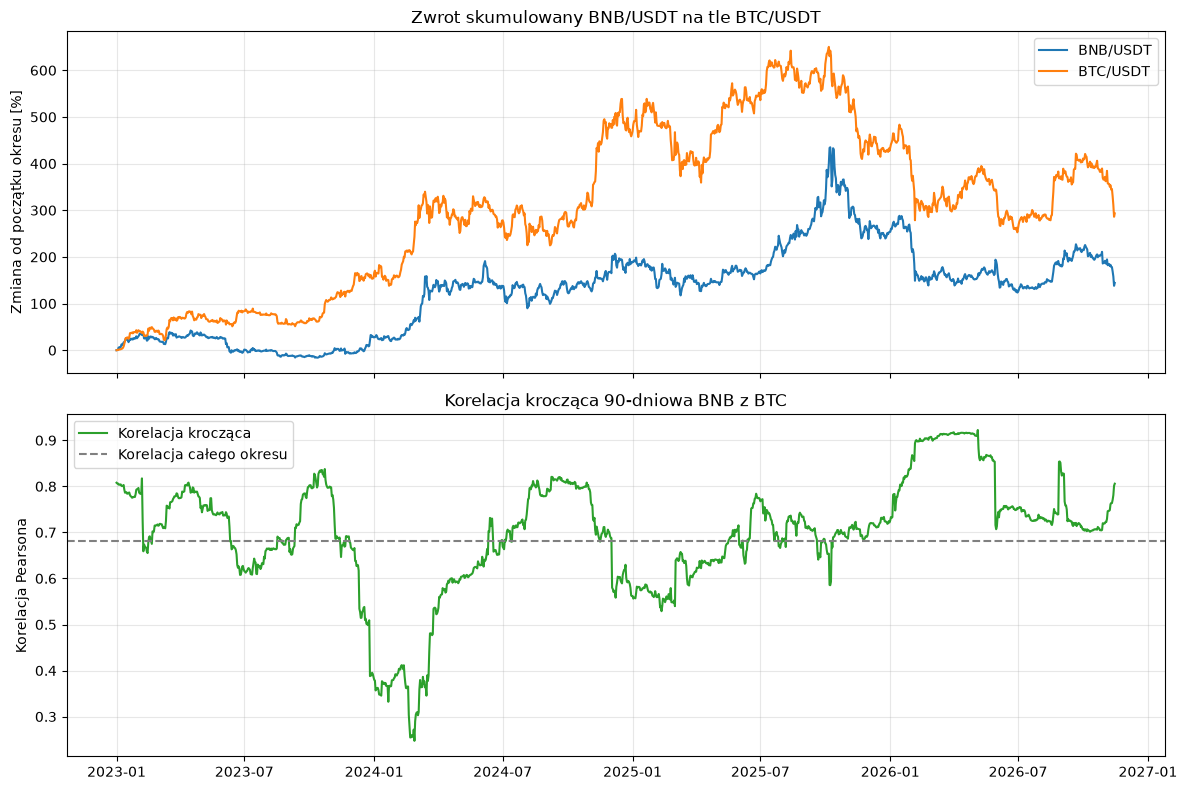

In [4]:
if not shared.empty:
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    for key, label in (("cum_bnb", "BNB/USDT"), ("cum_btc", "BTC/USDT")):
        series = res[key].asfreq("D")
        axes[0].plot(series.index, series * 100, label=label)
    axes[0].set_title("Zwrot skumulowany BNB/USDT na tle BTC/USDT")
    axes[0].set_ylabel("Zmiana od początku okresu [%]")
    axes[0].legend()

    rc = res["rolling_corr"]
    axes[1].plot(rc.index, rc, color="tab:green", label="Korelacja krocząca")
    if pd.notna(res["corr"]):
        axes[1].axhline(res["corr"], color="gray", linestyle="--", label="Korelacja całego okresu")
    axes[1].set_title("Korelacja krocząca 90-dniowa BNB z BTC")
    axes[1].set_ylabel("Korelacja Pearsona")
    axes[1].legend()

    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()